# ĐỀ TÀI: MÔ HÌNH AI DỰ ĐOÁN GIÁ NHÀ Ở PHƯỜNG PHÚ HÒA, TP. THỦ DẦU MỘT (phiên bản 2)

**Mã sinh viên:** 2324801030095
**Họ và tên:** Nguyễn Quang Long
**Lớp:** D23KTPM01
**Môn:** Học máy

**Bài toán:** cho thông tin một căn nhà (diện tích, kích thước, số tầng, số phòng, lối vào, vị trí, mô tả tin), mô hình dự đoán **giá bán (tỷ đồng)** kèm **khoảng giá tin cậy**, rồi **chẩn đoán** giá rao đang rẻ, hợp lý hay cao so với mặt bằng thị trường. Đây là bài toán **học có giám sát – hồi quy**.

**Phiên bản 2 khắc phục các hạn chế của phiên bản 1** (bản cũ lưu ở `ban_cu/`):

| Hạn chế ở phiên bản 1 | Cách khắc phục trong phiên bản 2 |
|---|---|
| Chỉ 170 căn, 1 nguồn (guland) | Thu thập thêm **Chợ Tốt Nhà** (API công khai, toàn Bình Dương cũ) và **alonhadat** (Thủ Dầu Một): ~1.500 căn sau làm sạch, Phú Hòa ~220 căn |
| Không có vị trí chi tiết | Tọa độ từ Chợ Tốt; tin không có tọa độ được gán theo **tuyến đường** → tính **giá khu vực** (k căn gần nhất, phường, tuyến đường) |
| Chưa khai thác phần mô tả tin | Đọc **từ khóa** (khu dân cư, hẻm xe hơi, sổ riêng/sổ chung, nhà nát, dãy trọ, bán gấp…) và **mô hình chữ TF‑IDF** xếp chồng (stacking) |
| Tin rác lẫn vào dữ liệu | Quy tắc làm sạch có giải thích: tin cho thuê, nhà lắp ghép, nhà ở xã hội, giá mồi ("2 tỷ xxx"), đất chưa thổ cư, đơn giá lệch > 3 lần khu vực; **sửa** diện tích nhập nhầm |
| Chỉ có 1 con số dự đoán | **Khoảng giá 80%** bằng conformal prediction, có kiểm tra độ phủ trên tập test |
| Chỉ thử mô hình mặc định | So sánh 7 mô hình (tuyến tính, Random Forest, LightGBM, CatBoost, stacking chữ, ensemble) bằng kiểm định chéo |

**Toàn bộ dữ liệu là tin rao thật, thu thập ngày 12–14/11/2026. Không có dữ liệu mô phỏng.**

**Quy trình:** 1. Thu thập → 2. Hợp nhất 3 nguồn → 3. Trích đặc trưng từ mô tả → 4. Làm sạch → 5. Gán tọa độ → 6. Khám phá dữ liệu → 7. Xây dựng mô hình → 8. Đánh giá trên tập test → 9. Khoảng tin cậy → 10. Chẩn đoán giá từng căn → 11. Lưu mô hình.

> Chạy lần lượt các ô từ trên xuống (Restart & Run All, khoảng 10–15 phút do có CatBoost và kiểm định chéo). Các lớp mô hình nằm trong `mo_hinh_gia.py` để mô hình đã lưu nạp lại được ở notebook khác.

## Bước 1: Thu thập dữ liệu

| Nguồn | Script | Phạm vi | Thông tin đặc biệt |
|---|---|---|---|
| guland.vn | `thu_thap/guland_thu_thap.js` (chạy trong trình duyệt) | Phường Phú Hòa | Bảng thông số chi tiết: loại hẻm, độ rộng hẻm, diện tích sàn |
| Chợ Tốt Nhà (nhatot.com) | `thu_thap/chotot_thu_thap.py` | Toàn Bình Dương cũ, loại "Nhà ở" | **Tọa độ**, ngang × dài, số tầng, phòng, WC, loại nhà, pháp lý, **giá gốc lúc đăng** |
| alonhadat.com.vn | `thu_thap/alonhadat_thu_thap.py` | TP. Thủ Dầu Một, loại nhà | Địa chỉ cũ kèm phường, kích thước, đường trước nhà, ngày đăng |

**Vì sao lấy cả khu vực ngoài Phú Hòa?** Mô hình học được quy luật chung (diện tích, số tầng, hẻm/mặt tiền… ảnh hưởng giá ra sao) từ nhiều căn hơn. Khác biệt về vị trí được mô hình xử lý bằng đặc trưng "giá khu vực". Bước 7 kiểm chứng điều này: huấn luyện trên toàn vùng cho sai số **trên chính các căn Phú Hòa** thấp hơn so với chỉ học trên Phú Hòa.

**Giới hạn:** giá là **giá rao bán**, chưa phải giá giao dịch. Không lưu tên, số điện thoại người đăng.

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from mo_hinh_gia import (khong_dau, trich_dac_trung_chu, MoHinhGia, XepChongChu, TrungBinhMoHinh,
                         BaselineDonGiaPhuong, chi_so_danh_gia)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

RANDOM_STATE = 42
DATA_DIR, MODEL_DIR = Path("data"), Path("model")
MODEL_DIR.mkdir(exist_ok=True)

raw_guland = pd.read_csv(DATA_DIR / "nha_phu_hoa_guland_raw.csv")
raw_chotot = pd.read_csv(DATA_DIR / "chotot_binh_duong_raw.csv")
raw_alon = pd.read_csv(DATA_DIR / "alonhadat_tdm_raw.csv")
pd.DataFrame({
    "Số tin": [len(raw_guland), len(raw_chotot), len(raw_alon)],
    "Ngày thu thập": [raw_guland["ngay_thu_thap"].iloc[0], raw_chotot["ngay_thu_thap"].iloc[0], raw_alon["ngay_thu_thap"].iloc[0]],
}, index=["guland (Phú Hòa)", "Chợ Tốt (Bình Dương cũ)", "alonhadat (Thủ Dầu Một)"])

,Số tin,Ngày thu thập
guland (Phú Hòa),190,2026-11-12
Chợ Tốt (Bình Dương cũ),2078,2026-11-14
alonhadat (Thủ Dầu Một),281,2026-11-14


In [2]:
print("Chợ Tốt - loại tin:", raw_chotot["loai_tin"].value_counts().to_dict())
print("Chợ Tốt - tin bán theo quận/huyện:")
raw_chotot[raw_chotot["loai_tin"] == "ban"]["quan_huyen"].value_counts().to_frame("Số tin bán")

Chợ Tốt - loại tin: {'ban': 1565, 'cho_thue': 513}
Chợ Tốt - tin bán theo quận/huyện:


,Số tin bán
quan_huyen,
Thành phố Thủ Dầu Một,439
Thành phố Dĩ An,428
Thành phố Thuận An,345
Thị xã Bến Cát,183
Thị xã Tân Uyên,138
Huyện Bàu Bàng,22
Huyện Dầu Tiếng,6
Huyện Phú Giáo,3
Huyện Bắc Tân Uyên,1


**Quan sát:** Chợ Tốt trả về cả **tin cho thuê** (giá theo tháng). Các tin này phải loại ngay, nếu không mô hình sẽ học nhầm giá thuê 5 triệu/tháng là giá bán. Tin bán tập trung ở Thủ Dầu Một, Dĩ An, Thuận An.

## Bước 2: Hợp nhất 3 nguồn về cùng một bảng
Mỗi nguồn đặt tên cột và đơn vị khác nhau. Ta đưa về một lược đồ chung (giá tỷ đồng, diện tích m², ngang/dài m, tên phường và tên đường viết thường không dấu để so khớp).

In [3]:
def so(x):
    # '5,5m' -> 5.5
    if pd.isna(x):
        return np.nan
    m = re.search(r"\d+(?:[.,]\d+)?", str(x))
    return float(m.group().replace(",", ".")) if m else np.nan

def ten_phuong(s):
    return None if pd.isna(s) else re.sub(r"^(phuong|xa|thi tran)\s*", "", khong_dau(s).strip()).strip()

def ten_duong(s):
    if pd.isna(s):
        return None
    s = re.sub(r"^(duong|d\.)\s+", "", khong_dau(s).strip())
    s = re.sub(r"\s*-\s*duong loai.*$", "", s).replace("30 thang 4", "30/4").replace("dt 743", "dt743")
    s = re.sub(r"^hem\s+\S+\s+", "", s)            # 'hẻm 453 lê hồng phong' -> 'lê hồng phong'
    return s.strip(" .,") or None

ten_quan = lambda s: re.sub(r"^(thanh pho|thi xa|huyen)\s+", "", khong_dau(s))

# --- guland ---
g = raw_guland
MA_VI_TRI = {"Hẻm nhỏ, sâu, cụt (< 2,5m)": 0, "Hẻm xe máy (2,5m ≤ rộng < 3,5m)": 1, "Hẻm 1 xe hơi (3,5m ≤ rộng < 5m)": 2,
             "Hẻm xe tải, 2 ô tô tránh (5m ≤ rộng < 7m)": 3, "Hẻm rất lớn, 2 xe tải tránh nhau (7m ≤ rộng < 10m)": 4,
             "Mặt đường chính": 5}
def tang_guland(r):
    k = r["tret_lau_mota"]
    if isinstance(k, str):
        if k == "cap4": return 1.0
        if k == "gac": return 1.5
        if k.startswith("1+"): return 1 + int(k[2:])
    return r["so_tang"]
G = pd.DataFrame({
    "nguon": "guland", "id": g["id"].astype(str), "url": g["url"], "ngay_dang": g["ngay_thu_thap"],
    "tieu_de": g["tieu_de"], "mo_ta": "", "gia_ty": g["gia"] / 1e9, "dt_dat": g["dt_dat"],
    "ngang": g["mat_tien"].replace(0, np.nan), "dai": g["chieu_dai"].replace(0, np.nan),
    "so_tang": g.apply(tang_guland, axis=1), "dt_san": g["dt_san"].replace(0, np.nan),
    "phong_ngu": g["phong_ngu"].fillna(g["pn_mota"]), "so_wc": g["phong_tam"].fillna(g["wc_mota"]),
    "mat_tien_duong": (g["vi_tri"] == "Mặt đường chính").astype(float).where(g["vi_tri"].notna()),
    "cap_loi_vao": g["vi_tri"].map(MA_VI_TRI), "hem_rong": g["hem_rong"].replace(0, np.nan),
    "quan": "thu dau mot", "phuong": "phu hoa", "duong": g["duong"].map(ten_duong),
    "lat": np.nan, "lon": np.nan, "toa_do_rieng": 0, "so_chung": np.nan,
    "noi_that": g["noi_that"].isin(["Đầy đủ nội thất", "Nội thất cơ bản"]).astype(float), "form_dac_diem": "",
})

# --- Chợ Tốt: chỉ tin bán ---
c = raw_chotot[raw_chotot["loai_tin"] == "ban"]
so_tin_cung_toa_do = c.groupby(["lat", "lon"])["id"].transform("size")
C = pd.DataFrame({
    "nguon": "chotot", "id": c["id"].astype(str), "url": c["url"], "ngay_dang": c["ngay_dang"],
    "tieu_de": c["tieu_de"], "mo_ta": c["mo_ta"].fillna(""), "gia_ty": c["gia"] / 1e9, "dt_dat": c["dt_dat"],
    "ngang": c["ngang"], "dai": c["dai"], "so_tang": c["so_tang"], "dt_san": c["dt_su_dung"],
    "phong_ngu": c["phong_ngu"], "so_wc": c["so_wc"],
    "mat_tien_duong": (c["loai_nha"] == "Nhà mặt tiền").astype(float),
    "cap_loi_vao": np.where(c["loai_nha"] == "Nhà mặt tiền", 5, np.nan), "hem_rong": np.nan,
    "quan": c["quan_huyen"].map(ten_quan), "phuong": c["phuong"].map(ten_phuong), "duong": c["duong"].map(ten_duong),
    "lat": c["lat"], "lon": c["lon"],
    # tọa độ "riêng" = gắn với 1 đối tượng bản đồ (osm) hoặc không bị dùng chung bởi nhiều tin (không phải tâm phường)
    "toa_do_rieng": (c["dia_chi_ma_vi_tri"].astype(str).str.startswith("osm") | (so_tin_cung_toa_do <= 3)).astype(int),
    "so_chung": c["phap_ly"].isin(["Sổ chung / công chứng vi bằng", "Giấy tờ viết tay"]).astype(float).where(c["phap_ly"].notna()),
    "noi_that": c["noi_that"].isin(["Nội thất đầy đủ", "Nội thất cao cấp"]).astype(float).where(c["noi_that"].notna()),
    "form_dac_diem": c["dac_diem"].fillna(""),
})

# --- alonhadat ---
a = raw_alon
kt = a["kich_thuoc"].fillna("").str.replace(",", ".").str.extract(r"([\d.]+)\s*x\s*([\d.]+)").astype(float)
dc = a["dia_chi_cu"].fillna("").str.split(",")
A = pd.DataFrame({
    "nguon": "alonhadat", "id": a["id"].astype(str), "url": a["url"], "ngay_dang": a["ngay_dang"],
    "tieu_de": a["tieu_de"], "mo_ta": a["mo_ta"].fillna(""), "gia_ty": pd.to_numeric(a["gia"]) / 1e9,
    "dt_dat": a["dt_dat"].map(so), "ngang": kt[0], "dai": kt[1], "so_tang": a["so_tang"].map(so), "dt_san": np.nan,
    "phong_ngu": a["phong_ngu"], "so_wc": np.nan,
    "mat_tien_duong": (a["loai_nha"] == "nha-mat-tien").astype(float),
    "cap_loi_vao": np.where(a["loai_nha"] == "nha-mat-tien", 5, np.nan), "hem_rong": a["duong_rong"].map(so),
    "quan": "thu dau mot", "phuong": dc.map(lambda p: ten_phuong(p[1]) if len(p) > 2 else None),
    "duong": dc.map(lambda p: ten_duong(p[0]) if len(p) > 2 else None),
    "lat": np.nan, "lon": np.nan, "toa_do_rieng": 0, "so_chung": np.nan, "noi_that": np.nan, "form_dac_diem": "",
})

df = pd.concat([G, C, A], ignore_index=True)
df["van_ban"] = (df["tieu_de"].fillna("") + " . " + df["mo_ta"].fillna("")).map(khong_dau)
print("Bảng hợp nhất:", df.shape)
df.groupby("nguon")[["dt_dat", "ngang", "dai", "so_tang", "dt_san", "phong_ngu", "so_wc", "hem_rong", "duong"]] \
  .agg(lambda s: s.notna().mean() * 100).round(0).T.rename_axis("% có dữ liệu")

Bảng hợp nhất: (2036, 27)


nguon,alonhadat,chotot,guland
% có dữ liệu,,,
dt_dat,100.0,95.0,100.0
ngang,88.0,76.0,69.0
dai,88.0,67.0,55.0
so_tang,89.0,62.0,92.0
dt_san,0.0,35.0,85.0
phong_ngu,99.0,91.0,67.0
so_wc,0.0,66.0,42.0
hem_rong,99.0,0.0,39.0
duong,91.0,76.0,53.0


**Quan sát:** Mỗi nguồn mạnh ở một chỗ: guland có diện tích sàn và độ rộng hẻm; Chợ Tốt có số WC, diện tích sử dụng; alonhadat gần như luôn có kích thước và đường trước nhà. Phần còn thiếu sẽ được bổ sung từ **mô tả tin** ở Bước 3.

## Bước 3: Trích đặc trưng từ tiêu đề và mô tả tin
Người đăng thường viết thông tin quan trọng trong phần mô tả chứ không điền vào ô thông số: "hẻm xe hơi 6m", "1 trệt 2 lầu", "khu dân cư", "sổ riêng", "bán gấp"… Hàm `trich_dac_trung_chu` (trong `mo_hinh_gia.py`) dùng biểu thức chính quy trên văn bản đã bỏ dấu để tạo:
- **Cờ 0/1:** hẻm xe hơi, hẻm nhỏ, mặt tiền, khu dân cư, đường nội bộ, nhà cấp 4, nhà nát, nhà mới, sổ riêng, sổ chung/vi bằng, chưa hoàn công, căn góc, kinh doanh được, dãy trọ, bán gấp, nội thất, nở hậu, thổ cư, thang máy, biệt thự, gần trung tâm.
- **Số đo:** độ rộng hẻm/đường, ngang, kích thước "5x20", số tầng (từ "x trệt y lầu"), phòng ngủ, WC, diện tích sàn, diện tích thổ cư.

In [4]:
T = trich_dac_trung_chu(df["van_ban"])
df = pd.concat([df, T], axis=1)

# Ô thông số trống -> lấy số đọc từ mô tả. Giá trị vô lý (ví dụ 30 tầng, 50 phòng ngủ) coi là thiếu.
df["ngang"] = df["ngang"].fillna(df["t_ngang"]).fillna(df["t_kt_ngang"])
df["dai"] = df["dai"].fillna(df["t_kt_dai"])
df["so_tang"] = df["so_tang"].where(df["so_tang"].between(1, 8)).fillna(df["t_so_tang"])
df["phong_ngu"] = df["phong_ngu"].where(df["phong_ngu"].between(1, 15)).fillna(df["t_pn"])
df["so_wc"] = df["so_wc"].where(df["so_wc"].between(1, 15)).fillna(df["t_wc"])
df["dt_san"] = df["dt_san"].fillna(df["t_dt_san"])
df["hem_rong"] = df["hem_rong"].where(df["hem_rong"].between(1.5, 60)).fillna(df["t_hem_rong"])
df["mat_tien_duong"] = df["mat_tien_duong"].fillna(df["t_mat_tien"])
df["so_chung"] = df["so_chung"].fillna(df["t_so_chung"])
df["noi_that"] = df["noi_that"].fillna(df["t_noi_that"])
f = df["form_dac_diem"]
df["t_hem_xe_hoi"] = (df["t_hem_xe_hoi"].astype(bool) | f.str.contains("Hẻm xe hơi")).astype(int)
df["t_no_hau"] = (df["t_no_hau"].astype(bool) | f.str.contains("nở hậu")).astype(int)
df["t_chua_hc"] = (df["t_chua_hc"].astype(bool) | f.str.contains("chưa hoàn công")).astype(int)
df["t_nha_nat"] = (df["t_nha_nat"].astype(bool) | f.str.contains("Nhà nát")).astype(int)

# Cấp lối vào 0..5 thống nhất cho mọi nguồn: hẻm nhỏ (0) ... mặt đường chính (5)
tu_do_rong = pd.cut(df["hem_rong"], [0, 2.5, 3.5, 5, 7, 10, 100], labels=[0, 1, 2, 3, 4, 4.5], right=False).astype(float)
cap = df["cap_loi_vao"].where(df["cap_loi_vao"].notna(), np.where(df["mat_tien_duong"] == 1, 5, np.nan))
cap = cap.fillna(tu_do_rong)
cap = cap.where(cap.notna(), np.where(df["t_hem_xe_hoi"] == 1, 2, np.where(df["t_hem_nho"] == 1, 0.5, np.nan)))
df["cap_loi_vao"] = cap

CO_CHU = [c for c in T.columns if T[c].dtype.kind == "i"]
(df[CO_CHU].mean() * 100).sort_values(ascending=False).round(1).to_frame("% số tin có nhắc tới").T

,t_tho_cu,t_trung_tam,t_kdc,t_so_rieng,t_hem_xe_hoi,t_mat_tien,t_kinh_doanh,t_ban_gap,t_noi_that,t_cap4,t_tro,t_nha_moi,t_goc,t_no_hau,t_biet_thu,t_so_chung,t_noi_bo,t_nha_nat,t_chua_hc,t_thang_may,t_hem_nho
% số tin có nhắc tới,45.1,33.3,27.2,23.6,21.7,16.7,16.5,16.5,16.1,12.6,11.3,11.1,7.5,6.9,3.5,2.7,2.6,1.6,1.0,0.7,0.3


**Quan sát:** Gần một nửa số tin nhắc tới "thổ cư", khoảng 1/4 nhắc "khu dân cư" và "sổ riêng", 1/6 có dấu hiệu "bán gấp / giảm giá". Đây là những thông tin phiên bản 1 chưa dùng tới (phiên bản 1 chỉ ra hạn chế: "chưa có đặc trưng khu dân cư").

## Bước 4: Làm sạch dữ liệu

### 4.1 Sửa diện tích nhập nhầm
Một số tin Chợ Tốt ghi **chiều dài vào ô diện tích** (ví dụ tiêu đề "5x28" nhưng diện tích = 28 m², đơn giá thành 70 triệu/m² ở vùng giá 15 triệu/m²). Nếu diện tích **trùng đúng** chiều dài (hoặc chiều ngang) và nhỏ hơn hẳn ngang × dài, ta sửa thành ngang × dài. Các trường hợp mơ hồ khác giữ nguyên.

In [5]:
nd = df["ngang"] * df["dai"]
ghi_nham = ((df["dt_dat"] - df["dai"]).abs() <= 1) | ((df["dt_dat"] - df["ngang"]).abs() <= 0.5)
sua = nd.between(25, 1000) & (df["dt_dat"].isna() | (ghi_nham & (df["dt_dat"] < 0.6 * nd)))
display(df.loc[sua, ["nguon", "tieu_de", "gia_ty", "dt_dat", "ngang", "dai"]].head(6))
df.loc[sua, "dt_dat"] = nd[sua]
print(f"Đã sửa diện tích cho {sua.sum()} tin")

,nguon,tieu_de,gia_ty,dt_dat,ngang,dai
210,chotot,"Nhà 5x21.5 full thổ cư tại Cát Tường Phú Hưng,...",1.599,21.50,5.0,21.50
214,chotot,"Bán nhà C4 đẹp, 5x30, 2.18 tỷ, D2 mp4, Bình Dương",2.180,30.00,5.0,30.00
221,chotot,"Nhà 1 lầu Trung tâm Uyên Hưng, Tân Uyên - 1.75 Tỷ",1.750,NaN,4.5,16.00
349,chotot,"Bán nhà 1 trệt 1 lầu gần THCS Hội Nghĩa, Bình ...",1.780,14.00,4.5,14.00
351,chotot,"Bán nhà Phước Điền 4.7x13m, 2.6 tỷ",2.600,NaN,4.7,13.00
361,chotot,"Nhà ở Chánh Nghĩa, Thủ Dầu 1, 3.3 tỷ",3.300,19.98,4.0,19.98


Đã sửa diện tích cho 84 tin


### 4.2 Lọc phạm vi nhà ở dân dụng và loại tin trùng
- Giữ giá 0,5–60 tỷ, diện tích đất 25–1.000 m², đơn giá 5–250 triệu/m².
- **Tin trùng:** cùng một căn thường được đăng ở nhiều trang hoặc đăng lại. Coi là trùng nếu cùng quận, cùng giá (làm tròn 10 triệu) và cùng diện tích (làm tròn 1 m²). Mỗi nhóm trùng chỉ giữ 1 dòng, **ô nào trống thì lấy từ bản trùng khác** (ví dụ lấy tọa độ từ Chợ Tốt, độ rộng hẻm từ guland).

In [6]:
n0 = len(df)
df = df[df["gia_ty"].between(0.5, 60) & df["dt_dat"].between(25, 1000)].copy()
df["don_gia"] = df["gia_ty"] * 1000 / df["dt_dat"]           # triệu/m² đất
df = df[df["don_gia"].between(5, 250)].copy()
n1 = len(df)
uu_tien = {"chotot": 0, "guland": 1, "alonhadat": 2}         # bản giữ lại ưu tiên nguồn có tọa độ
df = df.sort_values("nguon", key=lambda s: s.map(uu_tien), kind="stable")   # sắp xếp ổn định -> chạy lại cho cùng kết quả
df["nhom_trung"] = df.groupby(["quan", (df["gia_ty"] * 100).round(), df["dt_dat"].round()]).ngroup()
df["so_ban_trung"] = df.groupby("nhom_trung")["id"].transform("size")
df["cac_nguon"] = df.groupby("nhom_trung")["nguon"].transform(lambda s: "+".join(sorted(set(s))))
df = df.groupby("nhom_trung", as_index=False).first()
print(f"Ngoài phạm vi: {n0 - n1} tin | Trùng: {n1 - len(df)} tin | Còn lại: {len(df)} căn")
df["cac_nguon"].value_counts().head(6).to_frame("Số căn")

Ngoài phạm vi: 113 tin | Trùng: 345 tin | Còn lại: 1578 căn


,Số căn
cac_nguon,
chotot,1206
alonhadat,169
guland,138
alonhadat+chotot,36
chotot+guland,12
alonhadat+guland,11


**Quan sát:** Có nhiều tin trùng: cùng một căn được môi giới đăng ở cả Chợ Tốt, alonhadat và guland. Nếu không gộp lại, căn đó có thể vừa nằm trong tập train vừa nằm trong tập test, làm kết quả đánh giá **đẹp giả tạo**.

### 4.3 Gán tọa độ
Tọa độ là đầu vào cho đặc trưng "giá khu vực". Thứ tự ưu tiên:
1. Tọa độ riêng của tin trên Chợ Tốt (gắn với đối tượng bản đồ);
2. Tọa độ trung vị của **tuyến đường** đó (tính từ các tin Chợ Tốt có tọa độ riêng trên cùng đường). Nếu tin chưa ghi tên đường, tìm tên đường trong tiêu đề/mô tả (kể cả viết tắt NTMK, LHP);
3. Tâm **phường**; 4. Tâm quận.

Chỉ dùng vị trí, không dùng giá, nên bước này không làm rò rỉ nhãn.

In [7]:
co_xy = df[df["toa_do_rieng"] == 1]
xy_duong = co_xy.groupby(["quan", "duong"])[["lat", "lon"]].median()
xy_phuong = df.dropna(subset=["lat"]).groupby(["quan", "phuong"])[["lat", "lon"]].median()
xy_quan = df.dropna(subset=["lat"]).groupby("quan")[["lat", "lon"]].median()

ds_duong = sorted({d for d in xy_duong.index.get_level_values(1) if isinstance(d, str) and len(d) >= 6}, key=len, reverse=True)
VIET_TAT = {"ntmk": "nguyen thi minh khai", "lhp": "le hong phong", "dt743": "dt743"}
def tim_duong(t):
    for k, v in VIET_TAT.items():
        if re.search(rf"\b{k}\b", t):
            return v
    return next((d for d in ds_duong if d in t), None)
df["duong"] = df["duong"].fillna(df["van_ban"].map(tim_duong))

muc = []
for i, r in df.iterrows():
    if r["toa_do_rieng"] == 1:
        muc.append("1. tọa độ riêng"); continue
    if (r["quan"], r["duong"]) in xy_duong.index:
        df.loc[i, ["lat", "lon"]] = xy_duong.loc[(r["quan"], r["duong"])].values; muc.append("2. theo tuyến đường")
    elif (r["quan"], r["phuong"]) in xy_phuong.index:
        df.loc[i, ["lat", "lon"]] = xy_phuong.loc[(r["quan"], r["phuong"])].values; muc.append("3. tâm phường")
    else:
        df.loc[i, ["lat", "lon"]] = xy_quan.loc[r["quan"]].values; muc.append("4. tâm quận")
df["muc_toa_do"] = muc
TRUNG_TAM_TDM = (10.9805, 106.6520)       # chợ Thủ Dầu Một
df["kc_trung_tam_km"] = np.hypot((df["lat"] - TRUNG_TAM_TDM[0]) * 110.6, (df["lon"] - TRUNG_TAM_TDM[1]) * 109.3)
pd.crosstab(df["nguon"], df["muc_toa_do"])

muc_toa_do,1. tọa độ riêng,2. theo tuyến đường,3. tâm phường,4. tâm quận
nguon,,,,
alonhadat,0,90,74,5
chotot,378,285,597,0
guland,0,77,72,0


### 4.4 Loại tin không phản ánh giá nhà thị trường
Phân tích sai số ở bản nháp cho thấy phần lớn sai số rất lớn đến từ các tin **không phải giá một căn nhà ở bình thường**. Các quy tắc sau áp dụng như nhau cho mọi tin (cả train lẫn test), mỗi tin bị loại đều ghi lý do:

| Quy tắc | Lý do |
|---|---|
| Nhà gỗ lắp ghép, nhà tiền chế, "hoàn thiện toàn quốc" | Giá thi công, không phải giá bất động sản |
| Nhà ở xã hội | Giá do Nhà nước quy định, thị trường riêng |
| Giá mồi: "2 tỷ xxx", "giá 1,5 - 2 tỷ" | Số giá trên tin thấp hơn giá thật |
| Diện tích thổ cư < 50% diện tích đất | Phần lớn là đất nông nghiệp, đơn giá thấp hơn hẳn |
| Đơn giá lệch hơn **3 lần** so với trung vị 15 căn gần nhất | Gần như chắc chắn là lỗi nhập (sai đơn vị, nhầm diện tích) |

In [8]:
from sklearn.neighbors import BallTree

ly_do = pd.Series("", index=df.index)
def danh_dau(mask, s):
    ly_do[mask & (ly_do == "")] = s
v = df["van_ban"]
danh_dau(v.str.contains(r"\bnha go\b[^.\n]{0,20}(?:hien dai|lap|tam hop|thi cong)|lap ghep|tien che|toan quoc|nha container|thi cong tron goi|khung thep"),
         "Nhà lắp ghép / thi công")
danh_dau(v.str.contains(r"nha o xa hoi|\bnoxh\b"), "Nhà ở xã hội")
danh_dau(v.str.contains(r"\d\s*(?:ty|t)\s*x{2,}|gia[^\n\d]{0,12}\d+(?:[.,]\d+)?\s*(?:ty)?\s*-\s*\d+(?:[.,]\d+)?\s*ty\b"), "Giá mồi / không rõ ràng")
danh_dau(df["t_dt_tho_cu"] / df["dt_dat"] < 0.5, "Thổ cư < 50% diện tích")
xy = np.radians(df[["lat", "lon"]].to_numpy())
u = np.log(df["don_gia"].to_numpy())
_, idx = BallTree(xy, metric="haversine").query(xy, k=16)
lech = np.abs(u - np.median(u[idx[:, 1:]], axis=1)) > np.log(3)
danh_dau(pd.Series(lech, index=df.index), "Đơn giá lệch > 3 lần khu vực")
df["ly_do_loai"] = ly_do

bang_loai = df[ly_do != ""].groupby("ly_do_loai").agg(so_tin=("id", "size"), don_gia_tv=("don_gia", "median"))
display(bang_loai.round(1))
df[ly_do != ""][["nguon", "url", "tieu_de", "gia_ty", "dt_dat", "don_gia", "ly_do_loai"]].to_csv(
    DATA_DIR / "tin_bi_loai.csv", index=False, encoding="utf-8-sig")
df = df[ly_do == ""].reset_index(drop=True)
df["y"] = np.log(df["gia_ty"])
df["log_dt"] = np.log(df["dt_dat"])
df["ty_le_san"] = df["dt_san"] / df["dt_dat"]
df["phu_hoa"] = (df["phuong"] == "phu hoa").astype(int)
df["tdm"] = (df["quan"] == "thu dau mot").astype(int)
print(f"Còn {len(df)} căn | Thủ Dầu Một: {df['tdm'].sum()} | Phú Hòa: {df['phu_hoa'].sum()}  (danh sách tin bị loại: data/tin_bi_loai.csv)")

,so_tin,don_gia_tv
ly_do_loai,,
Giá mồi / không rõ ràng,21,38.5
Nhà lắp ghép / thi công,2,9.5
Nhà ở xã hội,19,35.0
Thổ cư < 50% diện tích,35,27.9
Đơn giá lệch > 3 lần khu vực,25,63.0


Còn 1476 căn | Thủ Dầu Một: 616 | Phú Hòa: 219  (danh sách tin bị loại: data/tin_bi_loai.csv)


**Quan sát:** Số tin bị loại nhỏ so với tổng, nhưng đây là những điểm có thể làm lệch mô hình mạnh nhất (ví dụ nhà lắp ghép 720 triệu được đăng như "bán nhà"). Danh sách tin bị loại và lý do được lưu ra `data/tin_bi_loai.csv` để có thể kiểm tra lại.

## Bước 5: Khám phá dữ liệu

In [9]:
tdm = df[df["tdm"] == 1]
bang = (tdm.groupby("phuong").agg(so_can=("y", "size"), gia_tv_ty=("gia_ty", "median"), don_gia_tv=("don_gia", "median"),
                                   dt_tv=("dt_dat", "median"))
        .query("so_can >= 8").sort_values("don_gia_tv", ascending=False))
bang.round(1)

,so_can,gia_tv_ty,don_gia_tv,dt_tv
phuong,,,,
phu cuong,8,6.4,52.0,96.0
hiep thanh,41,4.8,51.7,100.0
phu tho,16,4.2,43.5,125.0
hoa phu,30,5.0,42.9,123.0
phu my,55,3.9,42.2,100.0
phu loi,44,4.4,41.5,108.0
phu hoa,219,3.9,38.2,108.0
chanh nghia,30,4.2,38.1,110.0
dinh hoa,23,2.8,31.9,100.0


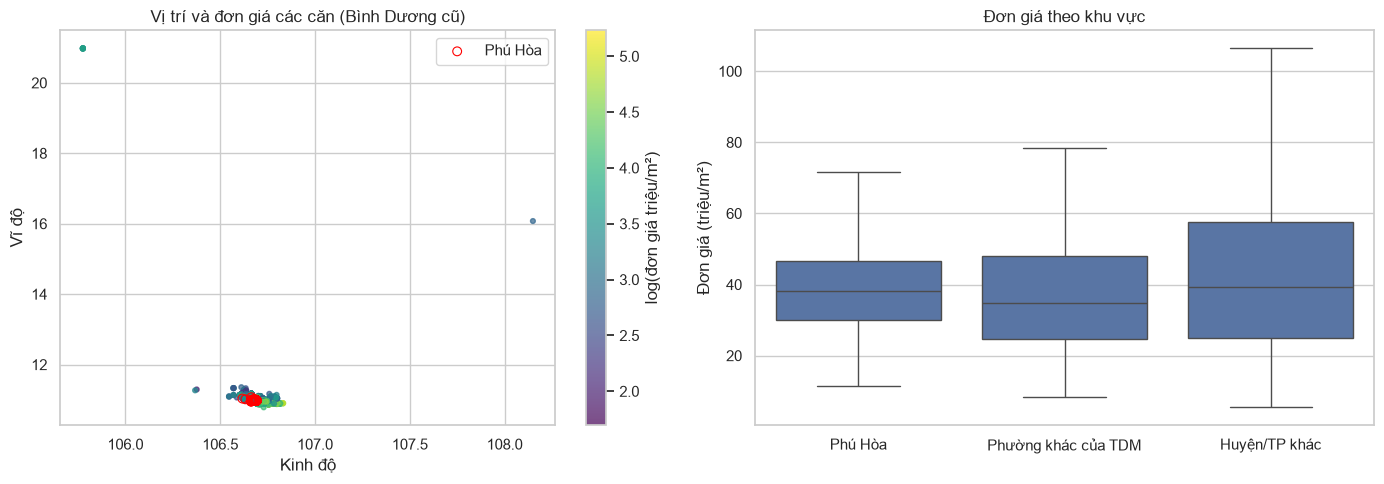

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
sc = ax.scatter(df["lon"], df["lat"], c=np.log(df["don_gia"]), cmap="viridis", s=12, alpha=0.7)
ph = df[df["phu_hoa"] == 1]
ax.scatter(ph["lon"], ph["lat"], facecolors="none", edgecolors="red", s=40, lw=0.8, label="Phú Hòa")
cb = plt.colorbar(sc, ax=ax); cb.set_label("log(đơn giá triệu/m²)")
ax.set(title="Vị trí và đơn giá các căn (Bình Dương cũ)", xlabel="Kinh độ", ylabel="Vĩ độ"); ax.legend()
ax = axes[1]
nhom = np.where(df["phu_hoa"] == 1, "Phú Hòa", np.where(df["tdm"] == 1, "Phường khác của TDM", "Huyện/TP khác"))
sns.boxplot(x=nhom, y=df["don_gia"], ax=ax, showfliers=False, order=["Phú Hòa", "Phường khác của TDM", "Huyện/TP khác"])
ax.set(title="Đơn giá theo khu vực", ylabel="Đơn giá (triệu/m²)", xlabel="")
plt.tight_layout(); plt.show()

**Quan sát:** Đơn giá phụ thuộc mạnh vào vị trí: cao ở lõi Thủ Dầu Một, Dĩ An, Thuận An (gần TP.HCM) và giảm dần về phía bắc (Bến Cát, Bàu Bàng). Phú Hòa nằm ở lõi Thủ Dầu Một, đơn giá trung vị cao hơn mặt bằng các phường khác. Vì vậy mô hình cần đặc trưng **giá khu vực** chứ không chỉ "tên phường".

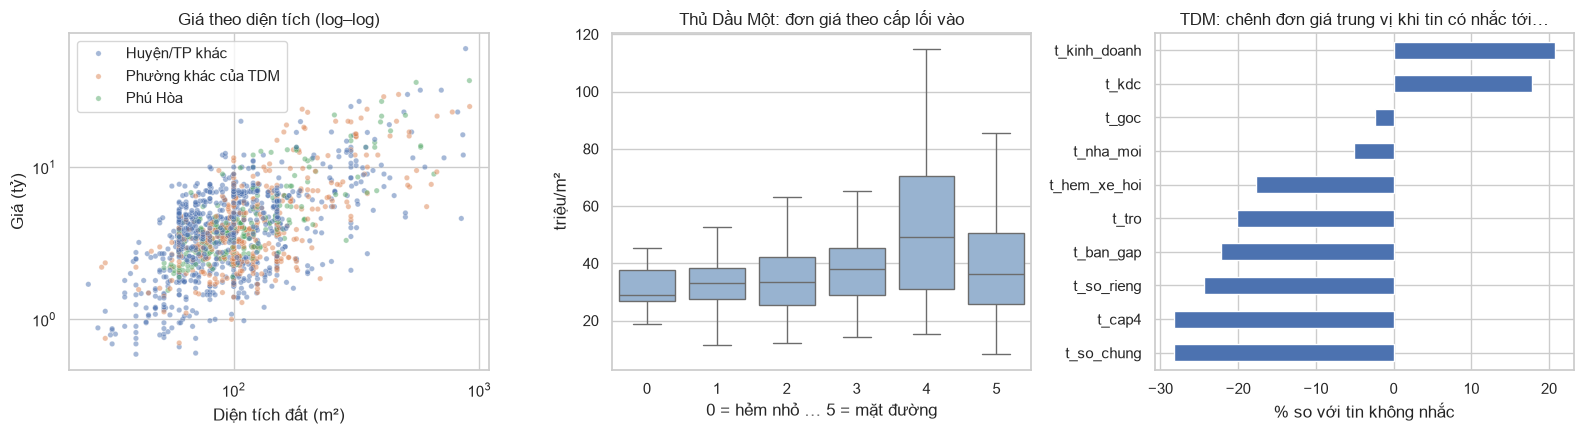

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.scatterplot(data=df, x="dt_dat", y="gia_ty", hue=nhom, alpha=0.5, s=15, ax=axes[0])
axes[0].set(xscale="log", yscale="log", title="Giá theo diện tích (log–log)", xlabel="Diện tích đất (m²)", ylabel="Giá (tỷ)")
lv = df.dropna(subset=["cap_loi_vao"]).assign(cap=lambda d: d["cap_loi_vao"].round().astype(int))
sns.boxplot(data=lv[lv["tdm"] == 1], x="cap", y="don_gia", showfliers=False, ax=axes[1], color="#8fb3d9")
axes[1].set(title="Thủ Dầu Một: đơn giá theo cấp lối vào", xlabel="0 = hẻm nhỏ … 5 = mặt đường", ylabel="triệu/m²")
anh_huong = {}
for c_ in ["t_kdc", "t_hem_xe_hoi", "t_so_rieng", "t_nha_moi", "t_cap4", "t_tro", "t_ban_gap", "t_so_chung", "t_kinh_doanh", "t_goc"]:
    co_, khong_ = tdm[tdm[c_] == 1]["don_gia"].median(), tdm[tdm[c_] == 0]["don_gia"].median()
    anh_huong[c_] = (co_ / khong_ - 1) * 100
pd.Series(anh_huong).sort_values().plot.barh(ax=axes[2], color="#4C72B0")
axes[2].set(title="TDM: chênh đơn giá trung vị khi tin có nhắc tới…", xlabel="% so với tin không nhắc")
plt.tight_layout(); plt.show()

**Quan sát:**
- Giá theo diện tích vẫn gần tuyến tính trên thang log–log → học trên **log(giá)** là hợp lý (sai số được đo theo tỷ lệ %).
- Đơn giá tăng theo cấp lối vào: hẻm nhỏ < hẻm xe hơi < mặt đường.
- Từ khóa trong mô tả có liên hệ rõ với đơn giá. Đây chỉ là so sánh thô (chưa tách ảnh hưởng của diện tích, vị trí), nên mô hình ở Bước 6 sẽ ước lượng tác động thật sự.

## Bước 6: Chia tập train / test
- **Tập test:** giữ riêng **20% số căn ở Thủ Dầu Một**, phân tầng theo (Phú Hòa hay không) × (5 mức giá) để test có đủ nhà rẻ/đắt và đủ căn Phú Hòa. Tập test chỉ dùng **một lần** ở Bước 8.
- **Tập train:** toàn bộ phần còn lại (gồm cả các huyện/TP khác).

In [12]:
from sklearn.model_selection import train_test_split

idx_tdm = df.index[df["tdm"] == 1]
tang = df.loc[idx_tdm, "phu_hoa"].astype(str) + "_" + pd.qcut(df.loc[idx_tdm, "y"], 5, labels=False).astype(str)
_, idx_test = train_test_split(idx_tdm, test_size=0.2, random_state=RANDOM_STATE, stratify=tang)
df["tap"] = np.where(df.index.isin(idx_test), "test", "train")
train, test = df[df["tap"] == "train"].reset_index(drop=True), df[df["tap"] == "test"].reset_index(drop=True)
pd.crosstab(df["tap"], np.where(df["phu_hoa"] == 1, "Phú Hòa", np.where(df["tdm"] == 1, "TDM khác", "Ngoài TDM")))

col_0,Ngoài TDM,Phú Hòa,TDM khác
tap,,,
test,0,43,81
train,860,176,316


## Bước 7: Xây dựng mô hình

**Đặc trưng đầu vào** (tất cả lấy được từ tin rao):
- Căn nhà: log(diện tích đất), ngang, dài, số tầng, diện tích sàn, tỷ lệ sàn/đất, phòng ngủ, WC, mặt tiền đường, cấp lối vào, độ rộng hẻm, sổ chung, nội thất.
- Vị trí: vĩ độ, kinh độ, khoảng cách tới trung tâm TDM, **giá khu vực** (`GiaLangGieng`: đơn giá của 12 căn gần nhất, của cùng phường, cùng tuyến đường – chỉ tính trên tập train, mỗi căn không được dùng giá của chính nó).
- Từ khóa trong mô tả (21 cờ ở Bước 3).
- (với mô hình stacking) **t_chu**: log(đơn giá) mà mô hình chữ TF‑IDF đọc được từ tiêu đề + mô tả.

**Các mô hình so sánh:**

| Mô hình | Ý tưởng |
|---|---|
| Baseline – đơn giá phường | Giá = đơn giá trung vị của phường × diện tích. Mốc tối thiểu phải vượt |
| Ridge | Hồi quy tuyến tính có phạt L2, học log(đơn giá) |
| Random Forest | Trung bình nhiều cây quyết định |
| LightGBM | Gradient boosting dạng histogram, nhanh, xử lý được giá trị thiếu |
| CatBoost | Gradient boosting với cây đối xứng, ít quá khớp khi dữ liệu nhỏ |
| LightGBM Huber + chữ | LightGBM với **hàm mất mát Huber** (ít bị kéo lệch bởi tin giá ảo) + đặc trưng từ mô hình chữ |
| Ensemble + chữ | Trung bình LightGBM Huber, CatBoost và Ridge, cùng đặc trưng chữ |

**Đánh giá:** kiểm định chéo 5-fold trên tập train. Chỉ số tính trên **các căn Phú Hòa** (mục tiêu đề tài) và trên **toàn Thủ Dầu Một**:
- **MAPE:** sai số % trung bình; **MdAPE:** sai số % trung vị (một nửa số căn sai ít hơn mức này, ít bị ảnh hưởng bởi vài tin giá ảo);
- **Trong ±10% / ±20%:** tỷ lệ căn đoán đúng trong biên độ đó; **R²** trên giá tỷ đồng.

In [13]:
from sklearn.model_selection import KFold
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

DAC_TRUNG = ["log_dt", "ngang", "dai", "so_tang", "dt_san", "ty_le_san", "phong_ngu", "so_wc", "mat_tien_duong",
             "cap_loi_vao", "hem_rong", "so_chung", "noi_that", "lat", "lon", "kc_trung_tam_km"] + CO_CHU
DAC_TRUNG_CHU = DAC_TRUNG + ["t_chu"]

lgb = lambda **k: LGBMRegressor(n_estimators=600, learning_rate=0.02, num_leaves=15, min_child_samples=10, subsample=0.8,
                                subsample_freq=1, colsample_bytree=0.6, reg_lambda=1.0, verbose=-1, random_state=0, **k)
cat = lambda: CatBoostRegressor(iterations=1500, learning_rate=0.03, depth=6, l2_leaf_reg=5, verbose=0, random_seed=0, thread_count=8)
ridge = lambda f: MoHinhGia(RidgeCV(alphas=np.logspace(-2, 3, 30)), f, chuan_hoa=True, muc_tieu="don_gia")

MO_HINH = {
    "Baseline (đơn giá phường)": lambda: BaselineDonGiaPhuong(),
    "Ridge": lambda: ridge(DAC_TRUNG),
    "Random Forest": lambda: MoHinhGia(make_pipeline(SimpleImputer(strategy="median"),
                                       RandomForestRegressor(500, min_samples_leaf=2, max_features=0.4, n_jobs=-1, random_state=0)), DAC_TRUNG),
    "LightGBM": lambda: MoHinhGia(lgb(), DAC_TRUNG),
    "CatBoost": lambda: MoHinhGia(cat(), DAC_TRUNG, muc_tieu="don_gia"),
    "LightGBM Huber + chữ": lambda: XepChongChu(MoHinhGia(lgb(objective="huber", alpha=0.25, ), DAC_TRUNG_CHU)),
    "Ensemble + chữ": lambda: XepChongChu(TrungBinhMoHinh([MoHinhGia(lgb(objective="huber", alpha=0.25), DAC_TRUNG_CHU),
                                                         MoHinhGia(cat(), DAC_TRUNG_CHU, muc_tieu="don_gia"),
                                                         ridge(DAC_TRUNG_CHU)])),
}

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
OOF = {}
for ten, tao in MO_HINH.items():
    p = np.zeros(len(train))
    for tr, va in kfold.split(train):
        p[va] = tao().fit(train.iloc[tr], train["y"].iloc[tr]).predict(train.iloc[va])
    OOF[ten] = p
    print("xong:", ten)

def bang_ket_qua(du_doan, khung, mask):
    return pd.DataFrame({t: chi_so_danh_gia(khung["y"][mask], p[mask]) for t, p in du_doan.items()}).T

bang_cv_ph = bang_ket_qua(OOF, train, (train["phu_hoa"] == 1).to_numpy()).sort_values("MAPE (%)")
bang_cv_tdm = bang_ket_qua(OOF, train, (train["tdm"] == 1).to_numpy()).sort_values("MAPE (%)")
print("Kiểm định chéo – các căn PHÚ HÒA trong tập train:"); display(bang_cv_ph.round(3))
print("Kiểm định chéo – các căn THỦ DẦU MỘT trong tập train:"); display(bang_cv_tdm.round(3))

xong: Baseline (đơn giá phường)


xong: Ridge


xong: Random Forest


xong: LightGBM


xong: CatBoost


xong: LightGBM Huber + chữ


xong: Ensemble + chữ
Kiểm định chéo – các căn PHÚ HÒA trong tập train:


,MAE (tỷ),MAPE (%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),R²,Số căn
Ensemble + chữ,1.623,23.708,18.747,27.273,53.977,0.659,176.0
Ridge,1.637,23.990,19.115,26.136,50.568,0.646,176.0
LightGBM Huber + chữ,1.730,24.087,17.833,30.114,54.545,0.562,176.0
Random Forest,1.775,25.057,18.880,23.864,51.705,0.515,176.0
CatBoost,1.623,25.183,19.263,25.568,52.841,0.701,176.0
LightGBM,1.761,25.329,19.075,25.000,53.409,0.591,176.0
Baseline (đơn giá phường),1.815,30.423,24.407,26.136,45.455,0.642,176.0


Kiểm định chéo – các căn THỦ DẦU MỘT trong tập train:


,MAE (tỷ),MAPE (%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),R²,Số căn
LightGBM Huber + chữ,1.500,24.085,17.532,30.285,55.081,0.620,492.0
Ensemble + chữ,1.423,24.182,18.577,29.268,54.268,0.691,492.0
LightGBM,1.465,24.631,17.722,28.455,54.472,0.658,492.0
Random Forest,1.509,24.711,18.880,28.455,51.423,0.609,492.0
CatBoost,1.453,25.204,19.093,28.252,53.252,0.689,492.0
Ridge,1.529,27.268,21.106,25.203,46.951,0.679,492.0
Baseline (đơn giá phường),1.962,36.987,27.534,19.919,39.837,0.491,492.0


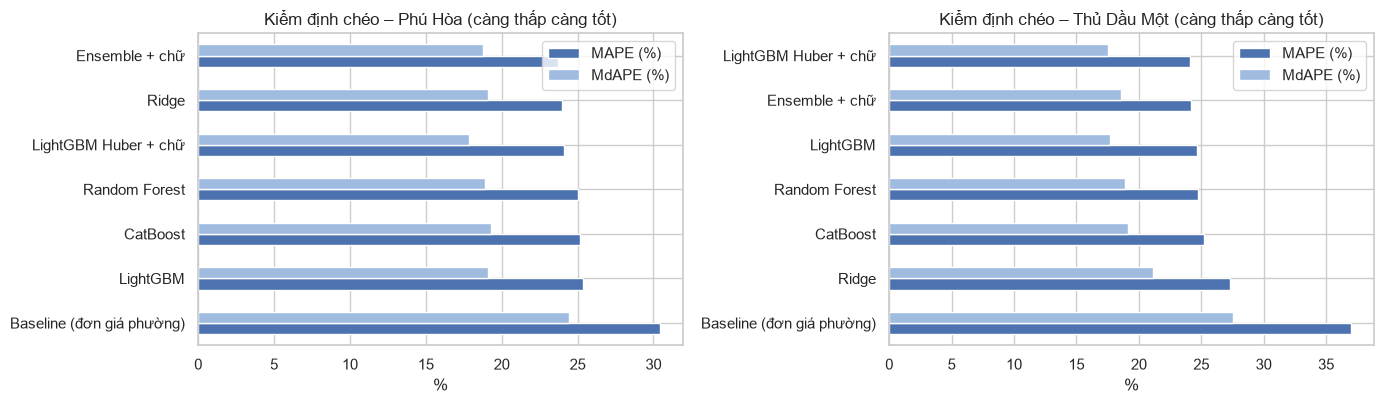

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (ten, b) in zip(axes, [("Phú Hòa", bang_cv_ph), ("Thủ Dầu Một", bang_cv_tdm)]):
    b2 = b[["MAPE (%)", "MdAPE (%)"]].sort_values("MAPE (%)", ascending=False)
    b2.plot.barh(ax=ax, color=["#4C72B0", "#9fbbe0"])
    ax.set(title=f"Kiểm định chéo – {ten} (càng thấp càng tốt)", xlabel="%")
plt.tight_layout(); plt.show()

**Kiểm chứng: học trên toàn vùng có tốt hơn chỉ học trên Phú Hòa?** Huấn luyện mô hình tốt nhất chỉ với các căn Phú Hòa của tập train, rồi so sai số trên chính các căn Phú Hòa (cùng cách chia fold).

In [15]:
# Tiêu chí chọn: trung bình MAPE kiểm định chéo trên các căn Phú Hòa và trên toàn TDM (xem giải thích bên dưới)
diem = ((bang_cv_ph["MAPE (%)"] + bang_cv_tdm["MAPE (%)"]) / 2).drop("Baseline (đơn giá phường)").sort_values()
display(diem.round(2).to_frame("MAPE TB (Phú Hòa, TDM)"))
ten_tot_nhat = diem.idxmin()
print("Mô hình được chọn:", ten_tot_nhat)

ph_train = train[train["phu_hoa"] == 1].reset_index(drop=True)
p_chi_ph = np.zeros(len(ph_train))
for tr, va in kfold.split(ph_train):
    p_chi_ph[va] = MO_HINH[ten_tot_nhat]().fit(ph_train.iloc[tr], ph_train["y"].iloc[tr]).predict(ph_train.iloc[va])
pd.DataFrame({
    "Chỉ học trên Phú Hòa": chi_so_danh_gia(ph_train["y"], p_chi_ph),
    "Học trên toàn vùng (Bước 7)": chi_so_danh_gia(train["y"][train["phu_hoa"] == 1], OOF[ten_tot_nhat][(train["phu_hoa"] == 1).to_numpy()]),
}).T.round(3)

,"MAPE TB (Phú Hòa, TDM)"
Ensemble + chữ,23.94
LightGBM Huber + chữ,24.09
Random Forest,24.88
LightGBM,24.98
CatBoost,25.19
Ridge,25.63


Mô hình được chọn: Ensemble + chữ


,MAE (tỷ),MAPE (%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),R²,Số căn
Chỉ học trên Phú Hòa,1.845,29.370,23.304,27.273,46.023,0.615,176.0
Học trên toàn vùng (Bước 7),1.623,23.708,18.747,27.273,53.977,0.659,176.0


**Quan sát:** Hai cách chia fold không hoàn toàn giống nhau (một cách chỉ có căn Phú Hòa), nhưng chênh lệch cho thấy rõ lợi ích: mô hình học từ vài trăm căn quanh khu vực ước lượng chính xác hơn so với chỉ học trên hơn 100 căn Phú Hòa. Đây là lý do phiên bản 2 mở rộng phạm vi thu thập.

**Chọn mô hình:** tiêu chí là **trung bình MAPE kiểm định chéo trên các căn Phú Hòa và trên toàn Thủ Dầu Một**. Chỉ dùng Phú Hòa (khoảng 175 căn trong tập train) thì chênh lệch dưới 1 điểm % giữa các mô hình nằm trong mức nhiễu, chạy lại với cách chia khác có thể đổi thứ hạng. Thêm TDM (gần 500 căn, gồm cả Phú Hòa) giúp lựa chọn ổn định hơn mà vẫn ưu tiên khu vực của đề tài. Mô hình được chọn được huấn luyện lại trên toàn bộ tập train.

## Bước 8: Đánh giá trên tập test
Tập test chưa được dùng ở bất kỳ bước nào. Ngoài baseline, so thêm với **cách làm của phiên bản 1**: Ridge trên 9 thông số căn nhà, chỉ học trên các căn Phú Hòa.

In [16]:
mo_hinh_tot = MO_HINH[ten_tot_nhat]().fit(train, train["y"])
baseline = BaselineDonGiaPhuong().fit(train, train["y"])
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
DT_V1 = ["dt_dat", "ngang", "so_tang", "dt_san", "phong_ngu", "so_wc", "cap_loi_vao", "hem_rong", "noi_that"]
v1 = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=3.0)).fit(ph_train[DT_V1], ph_train["y"])

p_test = {ten_tot_nhat: mo_hinh_tot.predict(test), "Baseline (đơn giá phường)": baseline.predict(test),
          "Cách làm phiên bản 1 (Ridge, chỉ Phú Hòa)": v1.predict(test[DT_V1])}
m_ph, m_tdm = (test["phu_hoa"] == 1).to_numpy(), np.ones(len(test), bool)
print("TẬP TEST – các căn Phú Hòa:"); display(bang_ket_qua(p_test, test, m_ph).round(3))
print("TẬP TEST – toàn bộ Thủ Dầu Một:"); display(bang_ket_qua(p_test, test, m_tdm).round(3))

TẬP TEST – các căn Phú Hòa:


,MAE (tỷ),MAPE (%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),R²,Số căn
Ensemble + chữ,1.142,17.244,13.150,41.860,67.442,0.715,43.0
Baseline (đơn giá phường),1.689,29.050,22.886,11.628,41.860,0.618,43.0
"Cách làm phiên bản 1 (Ridge, chỉ Phú Hòa)",2.119,32.069,18.901,20.930,55.814,-0.792,43.0


TẬP TEST – toàn bộ Thủ Dầu Một:


,MAE (tỷ),MAPE (%),MdAPE (%),Trong ±10% (%),Trong ±20% (%),R²,Số căn
Ensemble + chữ,1.308,22.591,15.842,29.839,58.065,0.734,124.0
Baseline (đơn giá phường),2.189,39.515,27.740,20.161,35.484,0.383,124.0
"Cách làm phiên bản 1 (Ridge, chỉ Phú Hòa)",2.844,45.256,25.697,18.548,42.742,-1.829,124.0


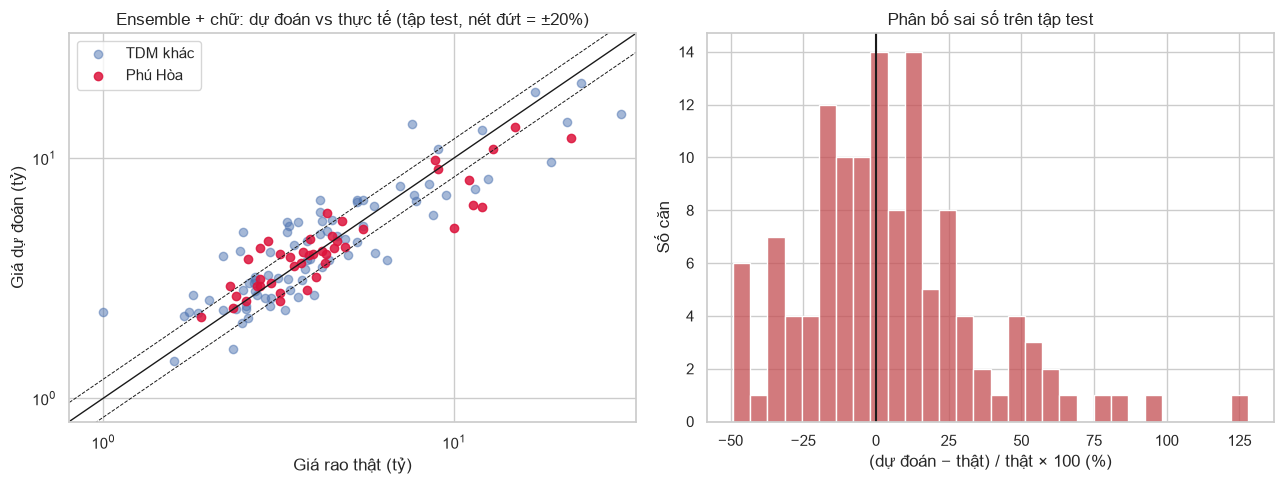

In [17]:
gia_that, gia_dd = test["gia_ty"].to_numpy(), np.exp(p_test[ten_tot_nhat])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.scatter(gia_that[~m_ph], gia_dd[~m_ph], alpha=0.5, label="TDM khác")
ax.scatter(gia_that[m_ph], gia_dd[m_ph], alpha=0.85, color="crimson", label="Phú Hòa")
lim = [0.8, max(gia_that.max(), gia_dd.max()) * 1.1]
ax.plot(lim, lim, "k-", lw=1); ax.plot(lim, [v * 1.2 for v in lim], "k--", lw=0.7); ax.plot(lim, [v / 1.2 for v in lim], "k--", lw=0.7)
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="Giá rao thật (tỷ)", ylabel="Giá dự đoán (tỷ)",
       title=f"{ten_tot_nhat}: dự đoán vs thực tế (tập test, nét đứt = ±20%)"); ax.legend()
sai_so = (gia_dd - gia_that) / gia_that * 100
sns.histplot(sai_so, bins=30, ax=axes[1], color="#C44E52"); axes[1].axvline(0, color="k")
axes[1].set(title="Phân bố sai số trên tập test", xlabel="(dự đoán − thật) / thật × 100 (%)", ylabel="Số căn")
plt.tight_layout(); plt.show()

**Đọc kết quả:** so sánh trên cùng tập test, mô hình phiên bản 2 tốt hơn rõ rệt cả baseline lẫn cách làm của phiên bản 1 (xem các bảng: MAPE, MdAPE, tỷ lệ căn trong ±20%). Cách làm phiên bản 1 có R² âm: mô hình tuyến tính học từ ít căn ngoại suy rất sai với vài căn lớn. Sai số trên test **không cao hơn** kiểm định chéo, nên không có dấu hiệu quá khớp. Tập test Phú Hòa chỉ có khoảng 40 căn nên con số dao động vài điểm %; khi trình bày nên nêu **cả hai** con số (kiểm định chéo và test).

Sai số trung vị khoảng 15–20% vẫn là mức thường gặp với **giá rao bán**: cùng một căn, các môi giới khác nhau rao chênh nhau 5–15%, người bán còn để "phần thương lượng". Phần sai số này nằm ở chính dữ liệu, mô hình không thể loại bỏ.

### Đặc trưng nào quan trọng?
Dùng **permutation importance theo nhóm** trên tập test: xáo trộn cùng lúc một nhóm cột rồi đo MAE trên log(giá) tăng bao nhiêu.

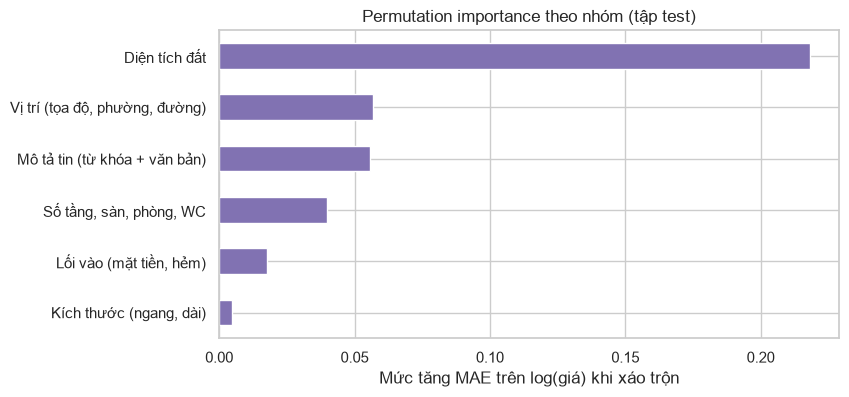

In [18]:
def mae_log(model, X):
    return np.mean(np.abs(model.predict(X) - X["y"].to_numpy()))

NHOM = {
    "Diện tích đất": ["log_dt", "dt_dat"], "Kích thước (ngang, dài)": ["ngang", "dai"],
    "Số tầng, sàn, phòng, WC": ["so_tang", "dt_san", "ty_le_san", "phong_ngu", "so_wc"],
    "Lối vào (mặt tiền, hẻm)": ["mat_tien_duong", "cap_loi_vao", "hem_rong", "t_hem_xe_hoi", "t_hem_nho", "t_mat_tien"],
    "Vị trí (tọa độ, phường, đường)": ["lat", "lon", "kc_trung_tam_km", "phuong", "duong"],
    "Mô tả tin (từ khóa + văn bản)": [c for c in CO_CHU if c not in ("t_hem_xe_hoi", "t_hem_nho", "t_mat_tien")] + ["van_ban", "so_chung", "noi_that"],
}
goc = mae_log(mo_hinh_tot, test)
rng = np.random.default_rng(0)
pi = {}
for ten, cols in NHOM.items():
    tang_ = []
    for _ in range(5):
        Xp = test.copy()
        perm = rng.permutation(len(Xp))
        for c_ in cols:
            Xp[c_] = Xp[c_].to_numpy()[perm]
        tang_.append(mae_log(mo_hinh_tot, Xp) - goc)
    pi[ten] = np.mean(tang_)
ax = pd.Series(pi).sort_values().plot.barh(color="#8172B2", figsize=(8, 4))
ax.set(title="Permutation importance theo nhóm (tập test)", xlabel="Mức tăng MAE trên log(giá) khi xáo trộn")
plt.show()

**Quan sát:** Diện tích đất vẫn là yếu tố số một. Nhóm **vị trí** (tọa độ, phường, đường, đưa vào mô hình qua đặc trưng giá khu vực) và nhóm **mô tả tin** đóng góp đáng kể; đây chính là hai nhóm thông tin phiên bản 1 còn thiếu.

## Bước 9: Khoảng giá tin cậy (conformal prediction)
Một con số dự đoán đơn lẻ chưa đủ để ra quyết định. Ta muốn khoảng [thấp, cao] **chứa giá thật của khoảng 80% số căn**.

**Cách làm (split-conformal trên sai số kiểm định chéo):** lấy sai số ngoài-fold của mô hình trên tập train, r = log(giá thật) − log(giá dự đoán). Phân vị 10% và 90% của r cho biên dưới/biên trên: khoảng = dự đoán × [e^q10, e^q90]. Sai số được đo trên dữ liệu mô hình **chưa thấy**, nên khoảng phản ánh đúng mức chắc chắn thật. Kiểm tra độ phủ trên tập test.

In [19]:
r = train["y"].to_numpy() - OOF[ten_tot_nhat]
Q = {k: float(np.quantile(r, q)) for k, q in [("q10", 0.10), ("q25", 0.25), ("q75", 0.75), ("q90", 0.90)]}
lo80, hi80 = p_test[ten_tot_nhat] + Q["q10"], p_test[ten_tot_nhat] + Q["q90"]
lo50, hi50 = p_test[ten_tot_nhat] + Q["q25"], p_test[ten_tot_nhat] + Q["q75"]
yt = test["y"].to_numpy()
pd.DataFrame({
    "Khoảng 80%": [np.mean((yt >= lo80) & (yt <= hi80)) * 100, np.mean(((yt >= lo80) & (yt <= hi80))[m_ph]) * 100,
                   f"{(np.exp(Q['q10']) - 1) * 100:+.0f}% … {(np.exp(Q['q90']) - 1) * 100:+.0f}%"],
    "Khoảng 50%": [np.mean((yt >= lo50) & (yt <= hi50)) * 100, np.mean(((yt >= lo50) & (yt <= hi50))[m_ph]) * 100,
                   f"{(np.exp(Q['q25']) - 1) * 100:+.0f}% … {(np.exp(Q['q75']) - 1) * 100:+.0f}%"],
}, index=["Độ phủ trên test TDM (%)", "Độ phủ trên test Phú Hòa (%)", "Biên độ quanh giá dự đoán"])

,Khoảng 80%,Khoảng 50%
Độ phủ trên test TDM (%),75.806452,50.0
Độ phủ trên test Phú Hòa (%),83.72093,65.116279
Biên độ quanh giá dự đoán,-29% … +40%,-15% … +18%


**Quan sát:** Độ phủ trên tập test gần với mức danh nghĩa (80% và 50%), nên có thể nói: *"với 80% độ tin cậy, giá thị trường của căn này nằm trong khoảng …"*. Khoảng 80% khá rộng (xem dòng "Biên độ", khoảng −30% … +40% quanh giá dự đoán) và **lệch lên trên** vì có những tin rao cao hơn hẳn mặt bằng. Đó là mức bất định thật của giá rao, báo cáo cần nêu rõ thay vì chỉ đưa một con số.

## Bước 10: Chẩn đoán giá từng căn ở Phú Hòa
Với **mỗi tin rao Phú Hòa**, so giá rao với giá thị trường mô hình ước lượng. Để công bằng, giá ước lượng của một căn được tính bằng mô hình **không học căn đó** (dự đoán ngoài-fold 5-fold trên toàn bộ dữ liệu).
- **Rẻ hơn thị trường:** giá rao thấp hơn biên dưới khoảng 80%.
- **Cao hơn thị trường:** giá rao cao hơn biên trên khoảng 80%.
- **Hợp lý:** nằm trong khoảng.

In [20]:
oof_all = np.zeros(len(df))
for tr, va in KFold(5, shuffle=True, random_state=7).split(df):
    oof_all[va] = MO_HINH[ten_tot_nhat]().fit(df.iloc[tr], df["y"].iloc[tr]).predict(df.iloc[va])
df["gia_uoc_luong_ty"] = np.exp(oof_all)
df["khoang80_thap"] = np.exp(oof_all + Q["q10"]); df["khoang80_cao"] = np.exp(oof_all + Q["q90"])
df["chenh_lech_pt"] = (df["gia_ty"] / df["gia_uoc_luong_ty"] - 1) * 100
df["chan_doan"] = np.select([df["gia_ty"] < df["khoang80_thap"], df["gia_ty"] > df["khoang80_cao"]],
                            ["Rẻ hơn thị trường", "Cao hơn thị trường"], "Hợp lý")
ph = df[df["phu_hoa"] == 1]
display(ph["chan_doan"].value_counts().to_frame("Số căn Phú Hòa"))
cot = ["nguon", "tieu_de", "dt_dat", "so_tang", "gia_ty", "gia_uoc_luong_ty", "khoang80_thap", "khoang80_cao", "chenh_lech_pt"]
print("5 căn giá rao thấp nhất so với thị trường:"); display(ph.sort_values("chenh_lech_pt")[cot].head(5).round(2))
print("5 căn giá rao cao nhất so với thị trường:"); display(ph.sort_values("chenh_lech_pt")[cot].tail(5).round(2))

,Số căn Phú Hòa
chan_doan,
Hợp lý,162
Cao hơn thị trường,36
Rẻ hơn thị trường,21


5 căn giá rao thấp nhất so với thị trường:


,nguon,tieu_de,dt_dat,so_tang,gia_ty,gia_uoc_luong_ty,khoang80_thap,khoang80_cao,chenh_lech_pt
819,guland,Bán nhà 287m² cấp 4 ngang 8m tại đường Phú Hòa...,287.0,1.0,3.30,8.42,5.98,11.75,-60.80
610,guland,Bán Nhà riêng 99m2 có sẵn 99 m2 thổ cư giá 1.9...,99.0,1.0,1.90,4.13,2.93,5.76,-54.00
947,chotot,"Bán nhà 4PN Phú Hòa 2, Thủ Dầu Một, Bình Dương...",210.0,3.0,4.19,8.68,6.17,12.12,-51.73
1081,guland,Bán nhà 382m² cấp 4 ngang 19m tại đường Nguyễn...,382.0,1.0,7.00,12.71,9.03,17.74,-44.92
1115,guland,"Đất mặt tiền Nguyễn Thị Minh Khai – 652,8 m² -...",652.8,1.0,9.00,15.82,11.24,22.08,-43.11


5 căn giá rao cao nhất so với thị trường:


,nguon,tieu_de,dt_dat,so_tang,gia_ty,gia_uoc_luong_ty,khoang80_thap,khoang80_cao,chenh_lech_pt
1183,guland,Bán Nhà riêng 257m2 có sẵn 200 m2 thổ cư giá 2...,257.0,3.0,22.0,9.81,6.97,13.70,124.20
1150,guland,Chính chủ cần tiền bán gấp nhà mặt tiền thích ...,180.0,NaN,13.0,5.43,3.86,7.58,139.49
1144,alonhadat,Bán mặt tiền Trần Văn Ơn Phú Hoà ngay Đại học ...,129.0,NaN,12.7,5.08,3.61,7.10,149.85
1142,guland,"Bán nhà mtkd lê hồng phong, 6x26m, có nhà lầu ...",142.0,NaN,12.5,4.75,3.38,6.63,163.14
1125,guland,"Bán nhà 106.5m² có sẵn 93m² thổ cư ngang 4,2m ...",106.5,NaN,9.9,3.53,2.51,4.93,180.14


In [21]:
xuat = ph.assign(dien_tich_m2=ph["dt_dat"]).rename(columns={"id": "ma_tin", "url": "link_tin", "gia_ty": "gia_rao_ty"})
xuat[["ma_tin", "nguon", "link_tin", "tieu_de", "dien_tich_m2", "ngang", "so_tang", "phong_ngu", "so_wc", "cap_loi_vao",
      "hem_rong", "duong", "t_kdc", "t_hem_xe_hoi", "t_so_rieng", "t_ban_gap"]].to_csv("input.csv", index=False, encoding="utf-8-sig")
xuat.assign(gia_du_doan_ty=xuat["gia_uoc_luong_ty"].round(3),
            khoang_80_ty=xuat["khoang80_thap"].round(2).astype(str) + " - " + xuat["khoang80_cao"].round(2).astype(str),
            chenh_lech_pt=xuat["chenh_lech_pt"].round(1), mo_hinh=ten_tot_nhat)[
    ["ma_tin", "nguon", "dien_tich_m2", "gia_rao_ty", "gia_du_doan_ty", "khoang_80_ty", "chenh_lech_pt", "chan_doan", "mo_hinh"]
].to_csv("output.csv", index=False, encoding="utf-8-sig")
print("Đã ghi input.csv (thông số", len(xuat), "căn Phú Hòa) và output.csv (giá ước lượng, khoảng 80%, chẩn đoán)")

Đã ghi input.csv (thông số 219 căn Phú Hòa) và output.csv (giá ước lượng, khoảng 80%, chẩn đoán)


**Quan sát:** Phần lớn căn Phú Hòa có giá rao "hợp lý" theo mô hình. Nhóm "cao hơn thị trường" thường là tin rao kỳ vọng cao hoặc có yếu tố mô hình không thấy (nhà mới xây cao cấp, vị trí đặc biệt). Nhóm "rẻ hơn" là ứng viên đáng xem (thường có tin "bán gấp/ngộp"), nhưng cũng cần kiểm tra pháp lý và hiện trạng. Kết quả là **gợi ý sàng lọc**, không thay thế thẩm định thực tế.

## Bước 11: Lưu mô hình và hàm dự đoán
- Huấn luyện lại mô hình đã chọn trên **toàn bộ** dữ liệu sạch → `model/mo_hinh_gia_nha.joblib` (kèm phân vị sai số để tính khoảng tin cậy).
- `model/mo_hinh_gia_nha.json`: **mô hình rút gọn** (Ridge, 11 thông số người dùng nhập được) cho trang demo `demo/trang_ban_nha.html` tính ngay trên trình duyệt. Mô hình này huấn luyện lại trên dữ liệu Phú Hòa mới, các thông số được **chặn trên ở phân vị 97%** để mô hình tuyến tính không ngoại suy quá đà. Sai số kiểm định chéo của nó được ghi kèm để trang demo hiển thị trung thực.
- `data/nha_da_xu_ly.csv`: dữ liệu sạch + giá ước lượng (notebook xu hướng dùng lại).

In [22]:
import json, joblib

mo_hinh_cuoi = MO_HINH[ten_tot_nhat]().fit(df, df["y"])
joblib.dump({"model": mo_hinh_cuoi, "ten": ten_tot_nhat, "phan_vi_sai_so": Q, "dac_trung": DAC_TRUNG,
             "ngay_du_lieu": "2026-11-14", "so_can": len(df)}, MODEL_DIR / "mo_hinh_gia_nha.joblib")

# --- mô hình rút gọn cho trang demo (cùng 11 đặc trưng như phiên bản 1) ---
ph_all = df[df["phu_hoa"] == 1].copy()
ph_all["duong_ntmk"] = ph_all["duong"].fillna("").str.contains("minh khai").astype(int)
ph_all["duong_lhp"] = ph_all["duong"].fillna("").str.contains("le hong phong").astype(int)
DEMO = {"dt_dat": "dt_dat", "mat_tien_x": "ngang", "so_tang_x": "so_tang", "dt_san_x": "dt_san", "phong_ngu_x": "phong_ngu",
        "so_wc": "so_wc", "vi_tri_cap": "cap_loi_vao", "hem_rong_x": "hem_rong", "duong_ntmk": "duong_ntmk",
        "duong_lhp": "duong_lhp", "noi_that_x": "noi_that"}
Xd = ph_all[list(DEMO.values())].astype(float); Xd.columns = list(DEMO)
# Mô hình tuyến tính ngoại suy rất sai với giá trị cực lớn (sàn 2.000 m², hẻm 60 m) -> chặn trên ở phân vị 97%.
# Trang web áp dụng đúng ngưỡng này trước khi tính (MODEL.clip_max).
CLIP = Xd.quantile(0.97)
Xd = Xd.clip(upper=CLIP, axis=1)
demo = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=3.0))
p_demo = np.zeros(len(Xd))
for tr, va in KFold(5, shuffle=True, random_state=RANDOM_STATE).split(Xd):
    p_demo[va] = demo.fit(Xd.iloc[tr], ph_all["y"].iloc[tr]).predict(Xd.iloc[va])
cv_demo = chi_so_danh_gia(ph_all["y"], p_demo)
demo.fit(Xd, ph_all["y"])
imp, sc, rg = demo.named_steps["simpleimputer"], demo.named_steps["standardscaler"], demo.named_steps["ridge"]
json.dump({"features": list(DEMO), "medians": imp.statistics_.tolist(), "model": "Ridge (rút gọn cho web)",
           "scaler": {"mean": sc.mean_.tolist(), "scale": sc.scale_.tolist()}, "type": "linear",
           "coef": rg.coef_.tolist(), "intercept": float(rg.intercept_), "cv_mape": round(cv_demo["MAPE (%)"], 1),
           "clip_max": CLIP.round(3).tolist(),
           "n_samples": int(len(Xd)), "mo_hinh_day_du": ten_tot_nhat,
           "mo_hinh_day_du_mape_test_phu_hoa": round(chi_so_danh_gia(test["y"][m_ph], p_test[ten_tot_nhat][m_ph])["MAPE (%)"], 1)},
          open(MODEL_DIR / "mo_hinh_gia_nha.json", "w", encoding="utf-8"), ensure_ascii=False)

json.dump({"ten_mo_hinh": ten_tot_nhat,
           "kiem_dinh_cheo_phu_hoa": bang_cv_ph.round(3).reset_index(names="Mô hình").to_dict("records"),
           "kiem_dinh_cheo_tdm": bang_cv_tdm.round(3).reset_index(names="Mô hình").to_dict("records"),
           "test_phu_hoa": bang_ket_qua(p_test, test, m_ph).round(3).reset_index(names="Mô hình").to_dict("records"),
           "test_tdm": bang_ket_qua(p_test, test, m_tdm).round(3).reset_index(names="Mô hình").to_dict("records"),
           "phan_vi_sai_so_log": Q, "mo_hinh_web": {"MAPE (%)": round(cv_demo["MAPE (%)"], 2), "Số căn": len(Xd)}},
          open(MODEL_DIR / "danh_gia_mo_hinh.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

luu = [c for c in df.columns if c not in ("van_ban", "mo_ta", "form_dac_diem")]
df[luu].to_csv(DATA_DIR / "nha_da_xu_ly.csv", index=False, encoding="utf-8-sig")
print("Mô hình web (Ridge rút gọn) – kiểm định chéo trên Phú Hòa:", {k: round(v, 2) for k, v in cv_demo.items()})
print("Đã lưu:", sorted(p.name for p in MODEL_DIR.iterdir()))

Mô hình web (Ridge rút gọn) – kiểm định chéo trên Phú Hòa: {'MAE (tỷ)': np.float64(1.48), 'MAPE (%)': np.float64(24.69), 'MdAPE (%)': np.float64(18.79), 'Trong ±10% (%)': np.float64(25.11), 'Trong ±20% (%)': np.float64(52.05), 'R²': np.float64(0.72), 'Số căn': 219}
Đã lưu: ['danh_gia_mo_hinh.json', 'mo_hinh_gia_nha.joblib', 'mo_hinh_gia_nha.json', 'xu_huong_gia.json']


Hàm dự đoán cho một căn nhà mới. Thông số nào không biết thì để `None`. Nếu không có tọa độ, hàm dùng tọa độ trung vị của tuyến đường (hoặc của phường Phú Hòa). Có thể dán **mô tả tin** vào `mo_ta` để mô hình đọc thêm thông tin.

In [23]:
goi = joblib.load(MODEL_DIR / "mo_hinh_gia_nha.joblib")

def du_doan_gia(dt_dat, ngang=None, dai=None, so_tang=None, dt_san=None, phong_ngu=None, so_wc=None,
                mat_tien_duong=0, cap_loi_vao=None, hem_rong=None, duong=None, phuong="phu hoa", quan="thu dau mot",
                lat=None, lon=None, mo_ta=""):
    van_ban = khong_dau(mo_ta)
    if lat is None:
        if duong and (quan, khong_dau(duong)) in xy_duong.index:
            lat, lon = xy_duong.loc[(quan, khong_dau(duong))].values
        else:
            lat, lon = xy_phuong.loc[(quan, phuong)].values
    can = pd.DataFrame([{"dt_dat": dt_dat, "ngang": ngang, "dai": dai, "so_tang": so_tang, "dt_san": dt_san,
                         "phong_ngu": phong_ngu, "so_wc": so_wc, "mat_tien_duong": mat_tien_duong, "cap_loi_vao": cap_loi_vao,
                         "hem_rong": hem_rong, "so_chung": np.nan, "noi_that": np.nan, "quan": quan, "phuong": phuong,
                         "duong": khong_dau(duong) if duong else None, "lat": lat, "lon": lon, "van_ban": van_ban}])
    can = pd.concat([can, trich_dac_trung_chu(can["van_ban"])], axis=1)
    can["log_dt"] = np.log(can["dt_dat"]); can["ty_le_san"] = can["dt_san"] / can["dt_dat"]
    can["kc_trung_tam_km"] = np.hypot((lat - TRUNG_TAM_TDM[0]) * 110.6, (lon - TRUNG_TAM_TDM[1]) * 109.3)
    can = can.astype({c_: float for c_ in ["ngang", "dai", "so_tang", "dt_san", "phong_ngu", "so_wc", "cap_loi_vao", "hem_rong"]})
    p = float(goi["model"].predict(can)[0]); q = goi["phan_vi_sai_so"]
    return {"gia_du_doan_ty": round(np.exp(p), 2), "khoang_80_ty": (round(np.exp(p + q["q10"]), 2), round(np.exp(p + q["q90"]), 2))}

vi_du = {
    "Nhà cấp 4, 100 m² (5x20), hẻm xe hơi 4m": dict(dt_dat=100, ngang=5, dai=20, so_tang=1, dt_san=100, phong_ngu=2, so_wc=1,
                                                     cap_loi_vao=2, hem_rong=4, mo_ta="nhà cấp 4 hẻm xe hơi sổ riêng"),
    "Nhà 1 trệt 1 lầu, 80 m², hẻm xe tải 6m, khu dân cư": dict(dt_dat=80, ngang=4.5, so_tang=2, dt_san=160, phong_ngu=3, so_wc=2,
                                                                cap_loi_vao=3, hem_rong=6, mo_ta="1 trệt 1 lầu kdc hẻm 6m sổ hồng riêng"),
    "Nhà 1 trệt 2 lầu, 120 m², mặt tiền Nguyễn Thị Minh Khai": dict(dt_dat=120, ngang=6, dai=20, so_tang=3, dt_san=300, phong_ngu=4,
                                                                     so_wc=4, mat_tien_duong=1, cap_loi_vao=5, hem_rong=20,
                                                                     duong="Nguyễn Thị Minh Khai", mo_ta="mặt tiền kinh doanh"),
}
pd.DataFrame({k: du_doan_gia(**v) for k, v in vi_du.items()}).T

,gia_du_doan_ty,khoang_80_ty
"Nhà cấp 4, 100 m² (5x20), hẻm xe hơi 4m",2.46,"(1.75, 3.44)"
"Nhà 1 trệt 1 lầu, 80 m², hẻm xe tải 6m, khu dân cư",3.74,"(2.66, 5.22)"
"Nhà 1 trệt 2 lầu, 120 m², mặt tiền Nguyễn Thị Minh Khai",7.54,"(5.36, 10.53)"


## Kết luận

**Kết quả đạt được**
- Dữ liệu **thật** từ 3 nguồn (guland, Chợ Tốt Nhà, alonhadat), thu thập 12–14/11/2026. Sau khi hợp nhất, sửa lỗi, loại trùng và loại tin không phải giá thị trường: khoảng 1.500 căn, trong đó Phú Hòa khoảng 220 căn. Không dùng dữ liệu mô phỏng.
- Mô hình được chọn bằng kiểm định chéo (xem tên ở Bước 7). Trên tập test chưa từng thấy, mô hình vượt rõ cả baseline đơn giá phường lẫn cách làm của phiên bản 1 (bảng Bước 8).
- Mỗi dự đoán có **khoảng giá 80%** đã kiểm chứng độ phủ trên tập test, và mỗi tin Phú Hòa có **chẩn đoán** rẻ / hợp lý / cao so với thị trường (`output.csv`).
- Yếu tố quyết định giá: diện tích đất, **vị trí** (giá khu vực), lối vào (hẻm → mặt đường), sau đó là các thông tin trong mô tả tin.

**Hạn chế còn lại (cần nêu khi trình bày)**
- Vẫn là **giá rao bán**, chưa phải giá giao dịch công chứng (dữ liệu này không công khai). Sai số trung vị khoảng 15–20% phần lớn đến từ độ "ảo" của giá rao.
- Tọa độ của tin guland/alonhadat chỉ chính xác tới **tuyến đường**; một số tin Chợ Tốt chỉ có tâm phường.
- Không có thông tin chất lượng xây dựng thật (vật liệu, tuổi nhà thực tế); chỉ đọc được gián tiếp qua mô tả ("nhà mới", "nhà nát").
- Mô hình phản ánh thị trường **tháng 11/2026**; cần cập nhật dữ liệu định kỳ (`thu_thap/cap_nhat_dinh_ky.py`). Xu hướng giá được phân tích ở notebook `du_doan_xu_huong_gia.ipynb`.